#  Data Splitting and K-Nearest Neighbours




## 1. Imports and key vocabulary
**X** contains input features. **y** contains the target labels. A binary target has two classes; a multiclass target has more than two classes but one label per sample. Multilabel classification allows several labels per sample. The main lab is binary classification.

**K in KNN is the number of neighbours.** It is not the number of cross-validation folds. This lab uses a fixed validation set; cross-validation is a later extension.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

SEED = 42
BLUE, ORANGE = '#2463a6', '#ce6a16'
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('NumPy:', np.__version__, '| pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)

NumPy: 2.3.5 | pandas: 2.2.3 | scikit-learn: 1.8.0


## 2. Reproduce the lecture: Walking or Running?
Slides 19–22 use two features: speed and movement intensity. For the new observation $X=(6,6.5)$, calculate the Euclidean distance to each training sample:

$$d(X,P_i)=\sqrt{\sum_{j=1}^{p}(X_j-P_{ij})^2}.$$

Select the nearest three samples and count their labels. We deliberately use **unscaled** features here to reproduce the slide arithmetic exactly. The full workflow later scales features using training data only.

,Speed,Intensity,Class,Distance
P4,7,7,Running,1.118
P2,5,5,Walking,1.803
P5,4,5,Walking,2.500
P3,8,9,Running,3.202
P1,3,4,Walking,3.905


,Votes
Class,
Walking,2
Running,1


Manual prediction: Walking
scikit-learn prediction: Walking


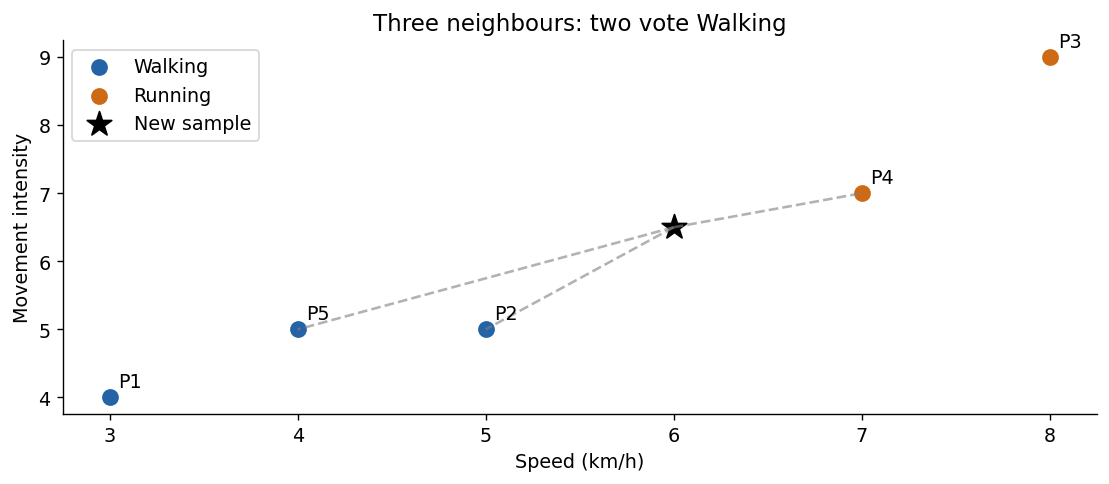

In [ ]:
activity = pd.DataFrame({
    'Speed': [3, 5, 8, 7, 4],
    'Intensity': [4, 5, 9, 7, 5],
    'Class': ['Walking', 'Walking', 'Running', 'Running', 'Walking']
}, index=['P1', 'P2', 'P3', 'P4', 'P5'])
query = np.array([6.0, 6.5])
features = ['Speed', 'Intensity']
activity['Distance'] = np.sqrt(((activity[features].to_numpy() - query) ** 2).sum(axis=1))
ranked = activity.sort_values('Distance')
neighbours = ranked.head(3)
display(ranked.round(3))
display(neighbours['Class'].value_counts().rename('Votes').to_frame())
manual_prediction = neighbours['Class'].mode().iloc[0]
print('Manual prediction:', manual_prediction)

small_knn = KNeighborsClassifier(n_neighbors=3, metric='euclidean', weights='uniform')
small_knn.fit(activity[features], activity['Class'])
query_df = pd.DataFrame([query], columns=features)
print('scikit-learn prediction:', small_knn.predict(query_df)[0])
assert manual_prediction == small_knn.predict(query_df)[0] == 'Walking'

fig, ax = plt.subplots()
for label, color in [('Walking', BLUE), ('Running', ORANGE)]:
    rows = activity[activity['Class'] == label]
    ax.scatter(rows['Speed'], rows['Intensity'], color=color, s=75, label=label)
for sample, row in activity.iterrows():
    ax.annotate(sample, (row['Speed'], row['Intensity']), xytext=(5, 6), textcoords='offset points')
for _, row in neighbours.iterrows():
    ax.plot([query[0], row['Speed']], [query[1], row['Intensity']], '--', color='gray', alpha=.6)
ax.scatter(*query, marker='*', s=220, color='black', label='New sample')
ax.set(xlabel='Speed (km/h)', ylabel='Movement intensity', title='Three neighbours: two vote Walking')
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** P4, P2 and P5 are closest. Their votes are Running, Walking and Walking, so the prediction is Walking. The label does not enter the distance calculation.

KNN is a **lazy, instance-based learner**: `fit` primarily stores/indexes training examples. It does not learn regression coefficients like a linear model. Generalization comes from the neighbourhood rule. Storing examples is therefore normal for KNN; high training accuracy alone still does not establish good generalization.


## 3. Load a real dataset and define X and y
We use the **Wisconsin Diagnostic Breast Cancer** dataset bundled with scikit-learn: 569 observations, 30 numerical features and two target classes. Features summarize measurements of cell nuclei from digitized images. This is a dataset demonstration, not a clinically validated prediction system.

The original encoding is **0 = malignant, 1 = benign**. To make the positive class explicit for precision and recall, we recode it to **1 = malignant (positive), 0 = benign (negative)**. We do not use `load_diabetes`, which is a regression dataset.

Only structural checks happen before splitting. Distribution exploration and learned preprocessing below use the training subset.

In [ ]:
dataset = load_breast_cancer(as_frame=True)
X = dataset.data.copy()
y = (dataset.target == 0).astype(int).rename('malignant')
class_names = ['Benign (0)', 'Malignant (1)']
print('X shape:', X.shape, '| y shape:', y.shape)
print('Original target names:', list(dataset.target_names))
print('Missing feature values:', int(X.isna().sum().sum()))
assert len(X) == len(y)
assert X.index.equals(y.index)
assert np.isfinite(X.to_numpy()).all()
assert set(y.unique()) == {0, 1}

X shape: (569, 30) | y shape: (569,)
Original target names: [np.str_('malignant'), np.str_('benign')]
Missing feature values: 0


## 4. Split the data: 60% train, 20% validation, 20% test
| Subset | Purpose | Permitted use |
|---|---|---|
| Train | Fit preprocessing and KNN | Store neighbours and estimate scaling parameters |
| Validation | Select K | Compare the predefined candidate models |
| Test | Evaluate the frozen final procedure | Final predictions after all choices are fixed |

We use two calls to `train_test_split`:
1. Reserve 20% for testing; 80% remains for development.
2. Take **25% of that remaining 80%** for validation: $0.25 \times 0.80 = 0.20$. This leaves $0.75 \times 0.80 = 0.60$ for training.

`test_size` means the fraction returned in the second subset by that function; in the second call, that subset is our **validation** set. `random_state` makes the split reproducible. `stratify=y` approximately preserves class proportions; it is appropriate here for a shuffled classification split.

For time-ordered data or repeated observations from the same person, use a time/group-aware split instead. A random split is not suitable for every dataset.

,Subset,Rows,Percent
0,Train,341,59.93
1,Validation,114,20.04
2,Test,114,20.04


No overlapping rows; feature/label alignment verified.


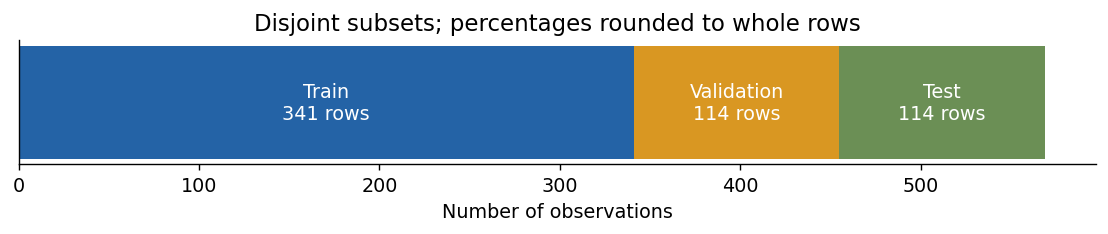

In [ ]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=SEED, stratify=y_dev
)

split_sizes = pd.DataFrame({
    'Subset': ['Train', 'Validation', 'Test'],
    'Rows': [len(X_train), len(X_val), len(X_test)]
})
split_sizes['Percent'] = 100 * split_sizes['Rows'] / len(X)
display(split_sizes.round(2))
# Audit membership without inspecting test features or outcomes.
train_ids, val_ids, test_ids = map(set, [X_train.index, X_val.index, X_test.index])
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)
assert train_ids | val_ids | test_ids == set(X.index)
for a, b in [(X_train, y_train), (X_val, y_val), (X_test, y_test)]:
    assert a.index.equals(b.index)
print('No overlapping rows; feature/label alignment verified.')

fig, ax = plt.subplots(figsize=(9, 2))
left = 0
for name, size, color in zip(split_sizes['Subset'], split_sizes['Rows'], [BLUE, '#d99722', '#6b8f55']):
    ax.barh(0, size, left=left, color=color)
    ax.text(left + size / 2, 0, f'{name}\n{size} rows', ha='center', va='center', color='white')
    left += size
ax.set(xlabel='Number of observations', yticks=[], title='Disjoint subsets; percentages rounded to whole rows')
plt.tight_layout()
plt.show()

**Expected sizes:** 341 training, 114 validation and 114 test observations. Exact percentages differ slightly from 60/20/20 because rows cannot be split into fractions.

The test set is reserved now. Its values and prediction performance will not guide any choices below.

## 5. Inspect the training data
Explore feature scales and class balance using the training subset. Accuracy alone can hide a weak model when one class is more common.

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
194,14.860,23.21,100.40,671.4,0.10440,0.19800,0.169700,0.088780,0.1737,0.06672,0.2796,0.9622,3.591,25.200,0.008081,0.05122,0.055510,0.018830,0.02545,0.004312,16.080,27.78,118.60,784.7,0.1316,0.46480,0.45890,0.17270,0.3000,0.08701
46,8.196,16.84,51.71,201.9,0.08600,0.05943,0.015880,0.005917,0.1769,0.06503,0.1563,0.9567,1.094,8.205,0.008968,0.01646,0.015880,0.005917,0.02574,0.002582,8.964,21.96,57.26,242.2,0.1297,0.13570,0.06880,0.02564,0.3105,0.07409
332,11.220,19.86,71.94,387.3,0.10540,0.06779,0.005006,0.007583,0.1940,0.06028,0.2976,1.9660,1.959,19.620,0.012890,0.01104,0.003297,0.004967,0.04243,0.001963,11.980,25.78,76.91,436.1,0.1424,0.09669,0.01335,0.02022,0.3292,0.06522
76,13.530,10.94,87.91,559.2,0.12910,0.10470,0.068770,0.065560,0.2403,0.06641,0.4101,1.0140,2.652,32.650,0.013400,0.02839,0.011620,0.008239,0.02572,0.006164,14.080,12.49,91.36,605.5,0.1451,0.13790,0.08539,0.07407,0.2710,0.07191
124,13.370,16.39,86.10,553.5,0.07115,0.07325,0.080920,0.028000,0.1422,0.05823,0.1639,1.1400,1.223,14.660,0.005919,0.03270,0.049570,0.010380,0.01208,0.004076,14.260,22.75,91.99,632.1,0.1025,0.25310,0.33080,0.08978,0.2048,0.07628


,Training count
malignant,
Benign,214
Malignant,127


,mean radius,mean area,mean smoothness
count,341.0000,341.0000,341.0000
mean,14.1634,659.6918,0.0957
std,3.5993,360.0732,0.0143
min,6.9810,143.5000,0.0643
25%,11.6700,417.2000,0.0847
50%,13.3400,551.1000,0.0951
75%,16.1400,809.8000,0.1044
max,27.4200,2501.0000,0.1634


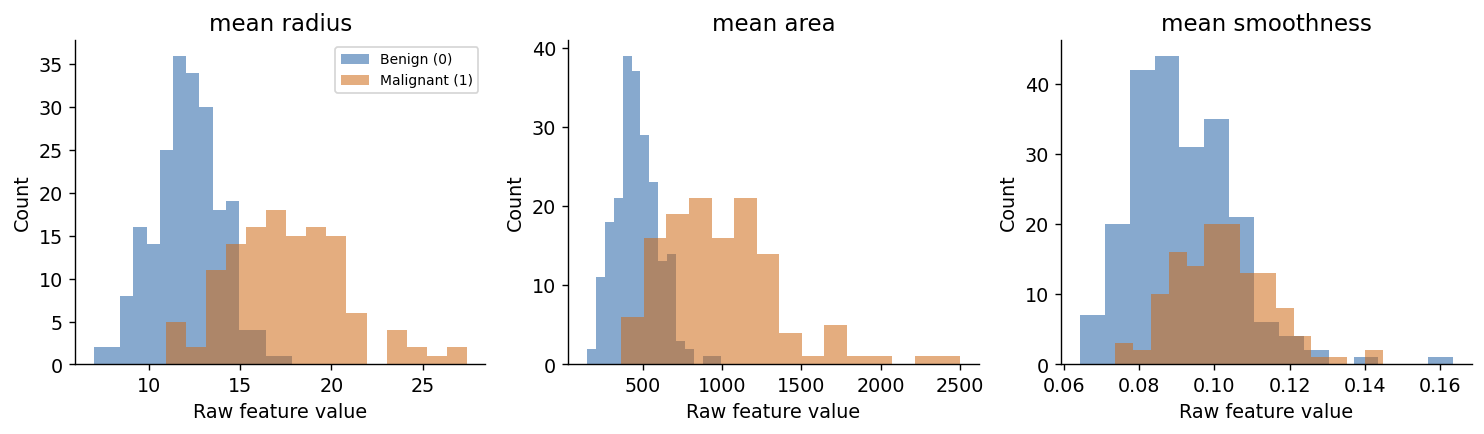

In [ ]:
display(X_train.head())
display(y_train.value_counts().sort_index().rename(index={0: 'Benign', 1: 'Malignant'}).to_frame('Training count'))
selected_features = ['mean radius', 'mean area', 'mean smoothness']
display(X_train[selected_features].describe().round(4))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, column in zip(axes, selected_features):
    for label, color in [(0, BLUE), (1, ORANGE)]:
        ax.hist(X_train.loc[y_train == label, column], bins=15, alpha=.55, color=color,
                label=class_names[label])
    ax.set(title=column, xlabel='Raw feature value', ylabel='Count')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Why scaling matters for KNN
Euclidean distance depends on units. A large numerical range can dominate the calculation even if that feature is not more informative.

`StandardScaler` transforms each feature separately:
$$x'_{ij}=\frac{x_{ij}-\mu_{j,\mathrm{train}}}{\sigma_{j,\mathrm{train}}}.$$

It uses population-style standard deviation (`ddof=0`). **Fit on training data; transform other data with those same parameters.** Never fit a scaler separately to validation or test data. Never fit it to the full dataset before splitting.

This is an important qualification to the lecture's preparation-before-splitting overview: schema checks can come first, but data-dependent transformations, imputation, feature selection and outlier thresholds must be learned within the training subset. We do not automatically remove outliers in this lab.

The following cell makes scaling visible. In the next section, a Pipeline carries out these same steps automatically.

In [ ]:
scaler_demo = StandardScaler()
X_train_scaled_demo = scaler_demo.fit_transform(X_train)
X_val_scaled_demo = scaler_demo.transform(X_val)
scaled_training = pd.DataFrame(X_train_scaled_demo, index=X_train.index, columns=X_train.columns)
display(pd.DataFrame({
    'Raw training mean': X_train[selected_features].mean(),
    'Raw training std (ddof=0)': X_train[selected_features].std(ddof=0),
    'Scaled training mean': scaled_training[selected_features].mean(),
    'Scaled training std (ddof=0)': scaled_training[selected_features].std(ddof=0)
}).round(4))
print('Validation means need not be zero: the scaler was fitted on training data.')

,Raw training mean,Raw training std (ddof=0),Scaled training mean,Scaled training std (ddof=0)
mean radius,14.1634,3.5940,0.0,1.0
mean area,659.6918,359.5448,-0.0,1.0
mean smoothness,0.0957,0.0143,0.0,1.0


Validation means need not be zero: the scaler was fitted on training data.


## 7. Fit a first KNN model and a baseline
A **Pipeline** combines scaling and KNN. Calling `fit(X_train, y_train)` fits its scaler and its neighbour model on the training subset. Calling `predict(X_val)` applies the learned scaler, then finds neighbours among the stored training observations.

We begin with K = 5. `weights='uniform'` gives each neighbour one vote; `metric='euclidean'` matches the lecture. Odd K avoids two-class vote ties with uniform voting, but odd K does not guarantee no ties for multiclass or weighted voting.

A majority-class baseline provides a simple reference. A model should offer more than always predicting the common class.

In [ ]:
def build_knn(k):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean'))
    ])

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
first_model = build_knn(5)
first_model.fit(X_train, y_train)
first_val_pred = first_model.predict(X_val)
display(pd.DataFrame({
    'Model': ['Majority baseline', 'Scaled KNN, K=5'],
    'Validation accuracy': [baseline.score(X_val, y_val), accuracy_score(y_val, first_val_pred)],
    'Validation F1 (positive=malignant)': [f1_score(y_val, baseline.predict(X_val), zero_division=0),
                                         f1_score(y_val, first_val_pred, zero_division=0)]
}).round(4))

,Model,Validation accuracy,Validation F1 (positive=malignant)
0,Majority baseline,0.6228,0.0000
1,"Scaled KNN, K=5",0.9737,0.9639


## 8. Choose K using validation data only
Before comparing models, set the selection rule: **maximize validation accuracy**; if several K values tie exactly, select the **smallest K** among them. This tie rule is a fixed teaching choice, not a universal preference.

We compare odd K values from 1 to 31, with all other settings fixed. The selection metric is chosen for the introductory exercise, not to establish clinical utility. For a different task, choose the metric based on the cost of errors **before** looking at results.

Training accuracy is diagnostic; it is not the selection criterion. At K=1, querying the training data usually retrieves each sample itself and can give perfect training accuracy. That is not an estimate of unseen-data performance.

,K,Training accuracy,Validation accuracy
0,1,1.0000,0.9474
1,3,0.9795,0.9649
2,5,0.9736,0.9737
3,7,0.9736,0.9737
4,9,0.9707,0.9737
5,11,0.9619,0.9737
6,13,0.9560,0.9737
7,15,0.9589,0.9737
8,17,0.9531,0.9737
9,19,0.9501,0.9737


Selected K: 5
Selection rule: highest validation accuracy; smallest K on an exact tie.


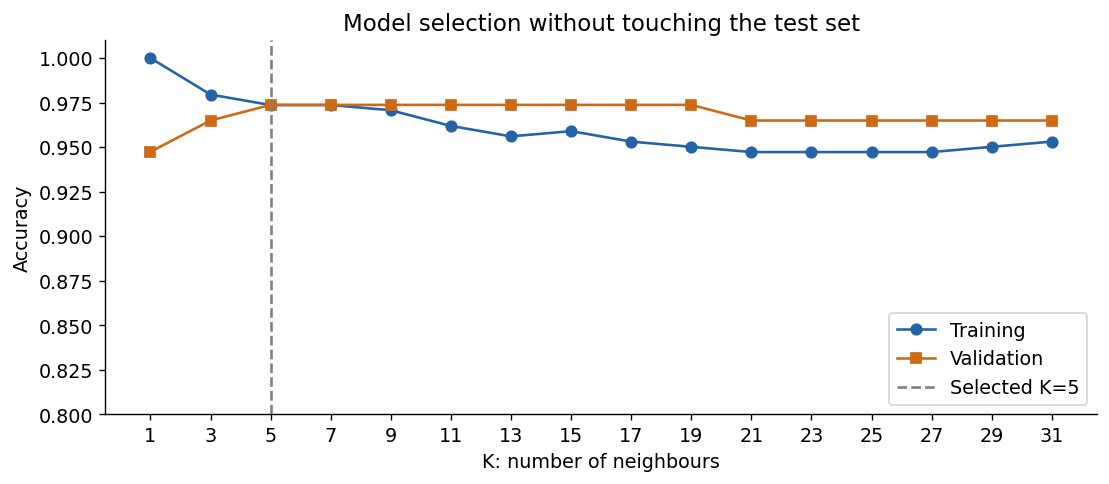

In [ ]:
candidate_ks = list(range(1, 32, 2))
assert max(candidate_ks) <= len(X_train)
rows = []
for k in candidate_ks:
    model = build_knn(k)
    model.fit(X_train, y_train)
    rows.append({'K': k,
                 'Training accuracy': model.score(X_train, y_train),
                 'Validation accuracy': model.score(X_val, y_val)})
results = pd.DataFrame(rows)
display(results.round(4))
ranked_results = results.sort_values(['Validation accuracy', 'K'], ascending=[False, True])
best_k = int(ranked_results.iloc[0]['K'])
print('Selected K:', best_k)
print('Selection rule: highest validation accuracy; smallest K on an exact tie.')

fig, ax = plt.subplots()
ax.plot(results['K'], results['Training accuracy'], 'o-', color=BLUE, label='Training')
ax.plot(results['K'], results['Validation accuracy'], 's-', color=ORANGE, label='Validation')
ax.axvline(best_k, color='gray', linestyle='--', label=f'Selected K={best_k}')
ax.set(xlabel='K: number of neighbours', ylabel='Accuracy', ylim=(0.80, 1.01),
       title='Model selection without touching the test set', xticks=candidate_ks)
ax.legend()
plt.tight_layout()
plt.show()

**Discussion:** A small K can follow noise, while a very large K can smooth away meaningful local structure. The curve need not be monotonic or show a perfect U shape. The best K depends on the data, preprocessing, split and metric. Repeatedly redesigning experiments around one validation set can also overfit that set; cross-validation is a later way to reduce dependence on a single split.

## 9. Look inside one validation prediction
Inspect the selected model before final evaluation. Transform the query using the fitted scaler before asking the internal KNN step for neighbours. Distances now refer to **standardized 30-dimensional features**, not raw measurements.

The validation label is displayed only to explain the result; it is not supplied to `predict` or used to calculate distances.

In [ ]:
selected_model = build_knn(best_k)
selected_model.fit(X_train, y_train)
example = X_val.iloc[[0]]  # Double brackets preserve the 2D input shape.
scaled_example = selected_model.named_steps['scaler'].transform(example)
distances, positions = selected_model.named_steps['knn'].kneighbors(scaled_example)
neighbour_table = pd.DataFrame({
    'Training row ID': X_train.index.to_numpy()[positions[0]],
    'Standardized distance': distances[0],
    'Class': y_train.iloc[positions[0]].to_numpy()
})
display(neighbour_table.round(3))
display(neighbour_table['Class'].value_counts().sort_index().to_frame('Votes'))
print('Predicted:', class_names[int(selected_model.predict(example)[0])])
print('Actual validation label:', class_names[int(y_val.iloc[0])])
print('Class order for predict_proba:', selected_model.classes_)
print('Neighbour vote proportions:', selected_model.predict_proba(example).round(3))

,Training row ID,Standardized distance,Class
0,344,1.340,0
1,519,1.651,0
2,249,1.714,0
3,394,2.057,0
4,422,2.058,0


,Votes
Class,
0,5


Predicted: Benign (0)
Actual validation label: Benign (0)
Class order for predict_proba: [0 1]
Neighbour vote proportions: [[1. 0.]]


`predict_proba` with uniform weights reports neighbour class proportions. These numbers are not automatically calibrated real-world probabilities.

## 10. Visualize the effect of K in two dimensions
This separate synthetic example illustrates the boundary shapes from slides 26–27. It uses no observations from the main test set and does not select the main model. Two-dimensional plots cannot display the full decision boundary of our 30-feature model.

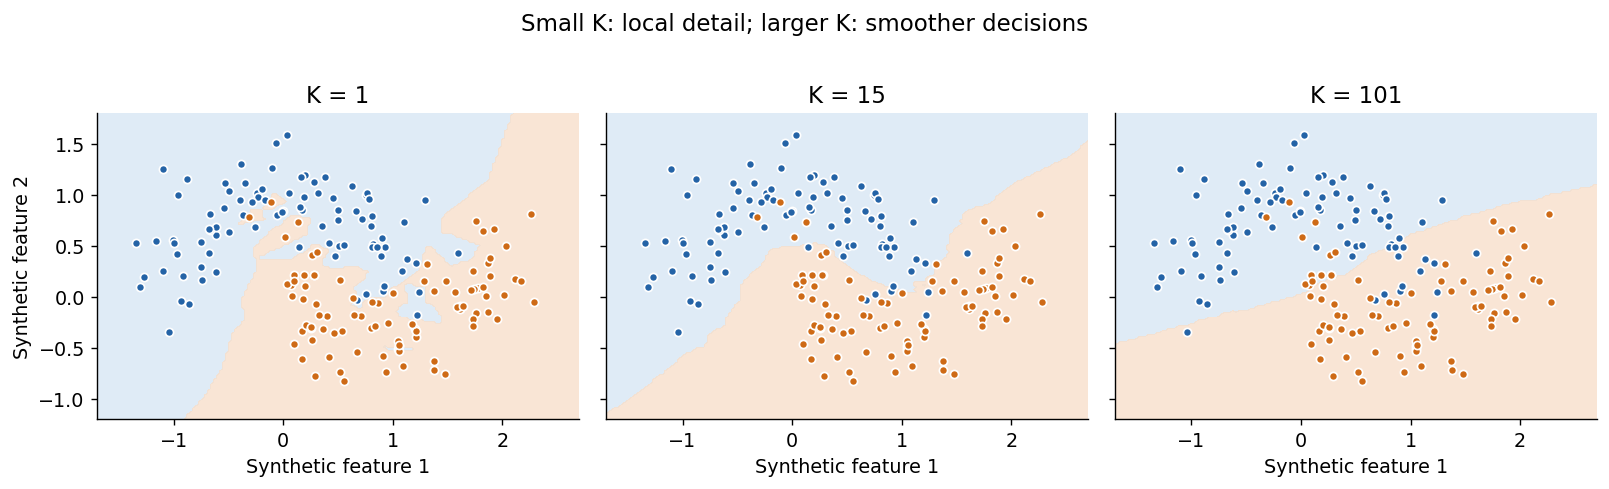

In [ ]:
X_visual, y_visual = make_moons(n_samples=180, noise=0.25, random_state=SEED)
x0, x1 = np.meshgrid(np.linspace(-1.7, 2.7, 160), np.linspace(-1.2, 1.8, 140))
grid = np.c_[x0.ravel(), x1.ravel()]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
for ax, k in zip(axes, [1, 15, 101]):
    visual_model = build_knn(k)
    visual_model.fit(X_visual, y_visual)
    boundary = visual_model.predict(grid).reshape(x0.shape)
    ax.contourf(x0, x1, boundary, levels=[-0.5, 0.5, 1.5], colors=['#d7e6f4', '#f8dfcb'], alpha=.8)
    for label, color in [(0, BLUE), (1, ORANGE)]:
        points = X_visual[y_visual == label]
        ax.scatter(points[:, 0], points[:, 1], color=color, edgecolors='white', s=22)
    ax.set(title=f'K = {k}', xlabel='Synthetic feature 1')
axes[0].set_ylabel('Synthetic feature 2')
fig.suptitle('Small K: local detail; larger K: smoother decisions', y=1.02)
plt.tight_layout()
plt.show()

## 11. Metrics: reproduce the 20-patient class activity
Slides 33–34 give TP=8, FP=3, FN=2 and TN=7. Positive means the condition is present.

$$Accuracy=\frac{TP+TN}{TP+TN+FP+FN},\qquad Precision=\frac{TP}{TP+FP}$$
$$Recall=\frac{TP}{TP+FN},\qquad F1=\frac{2TP}{2TP+FP+FN}.$$

**Axis convention:** scikit-learn uses rows = actual, columns = predicted. With `labels=[0,1]`, the matrix is `[[TN, FP], [FN, TP]]`. The lecture table places predicted values on rows and positive first. The counts and meanings are the same, but the layout differs. Always read the axis and class labels.

Accuracy asks how often the prediction is correct. Precision asks how many predicted positives are truly positive. Recall asks how many actual positives were found. F1 is the harmonic mean of precision and recall and does not include TN.

In [ ]:
activity_true = np.array([1]*8 + [0]*3 + [1]*2 + [0]*7)
activity_pred = np.array([1]*8 + [1]*3 + [0]*2 + [0]*7)
activity_cm = confusion_matrix(activity_true, activity_pred, labels=[0, 1])
TN, FP, FN, TP = activity_cm.ravel()
display(pd.DataFrame(activity_cm, index=['Actual negative', 'Actual positive'],
                     columns=['Predicted negative', 'Predicted positive']))
activity_metrics = pd.Series({
    'Accuracy': (TP + TN) / activity_cm.sum(),
    'Precision': TP / (TP + FP),
    'Recall': TP / (TP + FN),
    'F1': 2 * TP / (2 * TP + FP + FN)
})
display(activity_metrics.round(4))
assert (TN, FP, FN, TP) == (7, 3, 2, 8)
assert np.isclose(activity_metrics['F1'], f1_score(activity_true, activity_pred))

,Predicted negative,Predicted positive
Actual negative,7,3
Actual positive,2,8


Accuracy     0.7500
Precision    0.7273
Recall       0.8000
F1           0.7619
dtype: float64

**Expected answers:** accuracy = 0.75, precision ≈ 0.7273, recall = 0.80, F1 ≈ 0.7619. Here, F1 is not the arithmetic average of precision and recall.

## 12. Freeze the choice and refit on train + validation
K and all preprocessing choices are now fixed. We can use the combined development set (the original train + validation data) to fit a **fresh final pipeline**. Its scaler is refitted on that combined set, and its KNN model stores those observations.

This is permitted because validation has finished its selection role. The test set remains excluded. The old validation score described a model trained on 60% of the data; it is not a fresh evaluation of this refitted model.

Keeping the selected model trained only on the original training set would also be valid. Here we explicitly choose refitting to use more development examples.

In [ ]:
final_model = build_knn(best_k)
final_model.fit(X_dev, y_dev)
print(f'Final K={best_k}; fitted on {len(X_dev)} development observations.')
assert np.allclose(final_model.named_steps['scaler'].mean_, X_dev.mean().to_numpy())
print('All modelling choices are frozen. Next: final test evaluation.')

Final K=5; fitted on 455 development observations.
All modelling choices are frozen. Next: final test evaluation.


## 13. Final test evaluation
This is the first point where the main test features are supplied to a model for prediction. Generate predictions once, then reuse them for all metrics and the confusion matrix.

Positive = malignant (1). FP means benign predicted malignant; FN means malignant predicted benign. `zero_division=0` defines the reported value when a precision/recall denominator is zero; it does not solve the underlying absence of examples or predictions.

After seeing these results, do not tune K or preprocessing and claim the same test set is still unseen. Rerunning unchanged code is reproducibility; changing the model based on these results is test-set reuse.

Accuracy                   0.9561
Precision (malignant=1)    0.9744
Recall (malignant=1)       0.9048
F1 (malignant=1)           0.9383
Name: Final test score, dtype: float64

               precision    recall  f1-score   support

   Benign (0)      0.947     0.986     0.966        72
Malignant (1)      0.974     0.905     0.938        42

     accuracy                          0.956       114
    macro avg      0.961     0.945     0.952       114
 weighted avg      0.957     0.956     0.956       114

TN=71, FP=1, FN=4, TP=38


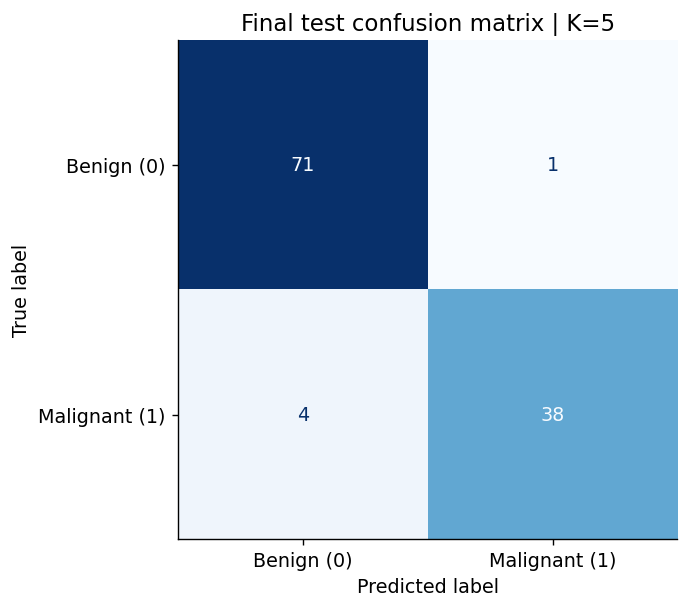

In [ ]:
test_pred = final_model.predict(X_test)
test_metrics = pd.Series({
    'Accuracy': accuracy_score(y_test, test_pred),
    'Precision (malignant=1)': precision_score(y_test, test_pred, pos_label=1, zero_division=0),
    'Recall (malignant=1)': recall_score(y_test, test_pred, pos_label=1, zero_division=0),
    'F1 (malignant=1)': f1_score(y_test, test_pred, pos_label=1, zero_division=0)
}, name='Final test score')
display(test_metrics.round(4))
print(classification_report(y_test, test_pred, labels=[0, 1], target_names=class_names,
                            digits=3, zero_division=0))
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')
fig, ax = plt.subplots(figsize=(6.5, 5))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Final test confusion matrix | K={best_k}')
plt.tight_layout()
plt.show()
assert cm.sum() == len(y_test)
assert np.isclose((tp + tn) / cm.sum(), test_metrics['Accuracy'])

**Reading the report:** per-class metrics treat each class as the positive class in turn. The macro average weights classes equally; the weighted average weights by the number of true examples (support). Neither should be confused with the positive-class F1 above.

A single holdout estimate has sampling uncertainty, and this small curated dataset does not establish performance in a different population. No single accuracy threshold proves that a model is good enough. Report the split, seed, selection rule, preprocessing and class definitions alongside scores.


## Optional extension A. Reproduce the lecture's KNN regression
Slides 23–25 use five houses with features area and bedrooms. The target is price in **thousands of dollars**. Calculate distances using the two features only, select three houses, and average their prices.

We retain raw units to match the lecture calculation. Area can dominate raw distance because its numerical range is much larger than bedrooms. A real workflow should decide on scaling using development data. This tiny example illustrates arithmetic; it does not estimate regression generalization.

In [ ]:
houses = pd.DataFrame({'Area': [90, 95, 105, 110, 130],
                       'Bedrooms': [2, 3, 3, 4, 4],
                       'Price_kUSD': [250, 270, 300, 320, 380]},
                      index=['H1', 'H2', 'H3', 'H4', 'H5'])
house_features = ['Area', 'Bedrooms']
new_house = pd.DataFrame([[102, 3]], columns=house_features)
houses['Distance'] = np.linalg.norm(houses[house_features].to_numpy() - new_house.to_numpy()[0], axis=1)
display(houses.sort_values('Distance').round(3))
manual_price = houses.sort_values('Distance').head(3)['Price_kUSD'].mean()
regressor = KNeighborsRegressor(n_neighbors=3, weights='uniform', metric='euclidean')
regressor.fit(houses[house_features], houses['Price_kUSD'])
model_price = regressor.predict(new_house)[0]
print(f'Manual: ${manual_price:.2f}k; scikit-learn: ${model_price:.2f}k')
assert np.isclose(manual_price, model_price)
assert np.isclose(model_price, 890 / 3)

,Area,Bedrooms,Price_kUSD,Distance
H3,105,3,300,3.000
H2,95,3,270,7.000
H4,110,4,320,8.062
H1,90,2,250,12.042
H5,130,4,380,28.018


Manual: $296.67k; scikit-learn: $296.67k


## Optional extension B. Solve the patient exercise with code
Slides 35–36 use generic feature coordinates for a synthetic activity. Predict the label at (5,5) with K=3. Try the calculation before running the solution.

In [ ]:
patients = pd.DataFrame({'Feature 1': [2, 3, 5, 6, 8, 7],
                         'Feature 2': [3, 4, 4, 6, 5, 2],
                         'Diabetes': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No']},
                        index=['P1', 'P2', 'P3', 'P4', 'P5', 'P6'])
patients['Distance'] = np.linalg.norm(patients[['Feature 1', 'Feature 2']].to_numpy() - [5, 5], axis=1)
patient_ranking = patients.sort_values('Distance', kind='stable')
display(patient_ranking.round(3))
patient_neighbours = patient_ranking.head(3)
print('Nearest:', list(patient_neighbours.index))
print('Votes:', patient_neighbours['Diabetes'].value_counts().to_dict())
print('Prediction:', patient_neighbours['Diabetes'].mode().iloc[0])
assert list(patient_neighbours.index) == ['P3', 'P4', 'P2']

,Feature 1,Feature 2,Diabetes,Distance
P3,5,4,Yes,1.000
P4,6,6,Yes,1.414
P2,3,4,No,2.236
P5,8,5,Yes,3.000
P1,2,3,No,3.606
P6,7,2,No,3.606


Nearest: ['P3', 'P4', 'P2']
Votes: {'Yes': 2, 'No': 1}
Prediction: Yes
